# Tugas 1 — Milestone 3: Analisis Temporal, Spasial, dan Advanced EDA

**Mata Kuliah:** Analisis Big Data  
**Target Check-in:** Pertemuan 8 (Mulai dikerjakan Pertemuan 6)  
**Nama Mahasiswa:** [Tuliskan Nama Anda]  
**NIM:** [Tuliskan NIM Anda]  
**Username GitHub:** [Tuliskan Username GitHub Anda]  

---

## Panduan Pengerjaan Milestone 3:
1. **Sumber Data:** Gunakan dataset yang telah dibersihkan pada Milestone 2 (`02_data_cleaning.ipynb`).
2. **Analisis Temporal / Windowing:** Terapkan minimal satu operasi temporal (Polars `group_by_dynamic()`, `rolling_mean()`, `shift()`, atau DuckDB window function `OVER (...)`).
3. **Visualisasi Interaktif:** Bangun minimal 6 visualisasi interaktif informatif menggunakan Plotly Express / Graph Objects atau Altair.
4. **Perumusan Insight:** Tuliskan minimal 5 temuan atau wawasan analitik mendalam berdasarkan hasil visualisasi data di atas.


## Bagian 1: Inisialisasi dan Memuat Data Bersih

Muat dataset hasil pembersihan dari folder `data/` menggunakan Polars.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import math

import numpy as np
import polars as pl
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown

HERE = Path.cwd().resolve()
PROJECT_ROOT = next(
    (d for d in [HERE, *HERE.parents]
     if (d / 'data' / 'processed' / 'qna_clean.parquet').is_file()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'data/processed/qna_clean.parquet tidak ditemukan. '
        'Jalankan dulu seluruh sel Milestone 2 sampai berhasil menulis hasil cleaning. '
        'Buka Jupyter dari root proyek atau folder notebooks/.'
    )

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
DATA_PATH = PROCESSED / 'qna_clean.parquet'
QUALITY_REPORT = PROCESSED / 'quality_report.json'
FIG_DIR = PROCESSED / 'eda_figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

MAX_POINTS = 15_000  # Sampel reproducible untuk visualisasi tingkat baris, BUKAN angka populasi
MAX_RESPONSE_HOURS = 30 * 24  # Batas tampilan 30 hari, tidak menghapus records dataset
raw = pl.scan_parquet(DATA_PATH)
cols = raw.collect_schema()
required = {
    'id', 'question_length', 'answer_length',
    'question_post_date_utc', 'answer_post_date_utc',
    'is_outlier_question_length', 'is_outlier_answer_length',
}
missing = sorted(required - set(cols.names()))
if missing:
    raise ValueError(
        f'Kolom hasil Milestone 2 tidak lengkap: {missing}. '
        'Pastikan notebook cleaning menghasilkan versi qna_clean.parquet yang benar.'
    )
for name in ('question_post_date_utc', 'answer_post_date_utc'):
    if cols[name].base_type() != pl.Datetime:
        raise TypeError(f'{name} harus bertipe Datetime, ditemukan {cols[name]}. Jalankan Milestone 2.')

print('Input    :', DATA_PATH)
print('Polars   :', pl.__version__)
print('Kolom    :', len(cols))
print('Output   :', FIG_DIR)

quality = None
if QUALITY_REPORT.exists():
    quality = json.loads(QUALITY_REPORT.read_text(encoding='utf-8'))
    print('Audit M2 : quality_report.json ditemukan')
else:
    print('PERINGATAN: quality_report.json belum ditemukan; audit M2 tidak dapat dibandingkan.')

Input    : /home/jovyan/work/data/processed/qna_clean.parquet
Polars   : 2.0.0
Kolom    : 17
Output   : /home/jovyan/work/data/processed/eda_figures
Audit M2 : quality_report.json ditemukan


In [2]:
metrics = (
    raw.select([
        'id', 'question_length', 'answer_length',
        'question_post_date_utc', 'answer_post_date_utc',
        'is_outlier_question_length', 'is_outlier_answer_length',
    ])
    .with_columns([
        pl.col('question_post_date_utc').dt.year().alias('year'),
        pl.col('question_post_date_utc').dt.weekday().alias('weekday_utc'),  # 1 = Senin
        pl.col('question_post_date_utc').dt.hour().alias('hour_utc'),
        (
            (pl.col('answer_post_date_utc') - pl.col('question_post_date_utc'))
            .dt.total_seconds().cast(pl.Float64) / 3600.0
        ).alias('response_hours'),
    ])
    .with_columns(
        pl.when(pl.col('question_post_date_utc').is_null() |
                pl.col('answer_post_date_utc').is_null())
          .then(pl.lit('Tanggal tidak lengkap'))
          .when(pl.col('response_hours') < 0)
          .then(pl.lit('Jawaban lebih awal'))
          .when(pl.col('response_hours') < 6)
          .then(pl.lit('0–<6 jam'))
          .when(pl.col('response_hours') < 24)
          .then(pl.lit('6–<24 jam'))
          .when(pl.col('response_hours') < 72)
          .then(pl.lit('1–<3 hari'))
          .when(pl.col('response_hours') < 168)
          .then(pl.lit('3–<7 hari'))
          .when(pl.col('response_hours') <= MAX_RESPONSE_HOURS)
          .then(pl.lit('7–30 hari'))
          .otherwise(pl.lit('>30 hari'))
          .alias('response_bucket')
    )
)
summary = metrics.select([
    pl.len().alias('jumlah_record'),
    pl.col('id').n_unique().alias('id_unik'),
    pl.col('question_post_date_utc').is_not_null().sum().alias('tanggal_pertanyaan_valid'),
    pl.col('answer_post_date_utc').is_not_null().sum().alias('tanggal_jawaban_valid'),
    (pl.col('response_hours') >= 0).sum().alias('jeda_nonnegatif'),
    (pl.col('response_hours') < 0).sum().alias('jeda_negatif'),
    pl.col('question_post_date_utc').min().alias('tanggal_awal'),
    pl.col('question_post_date_utc').max().alias('tanggal_akhir'),
    pl.col('question_length').median().alias('median_pertanyaan'),
    pl.col('answer_length').median().alias('median_jawaban'),
    pl.col('question_length').quantile(0.99).alias('p99_pertanyaan'),
    pl.col('answer_length').quantile(0.99).alias('p99_jawaban'),
    pl.col('is_outlier_question_length').sum().alias('outlier_pertanyaan'),
    pl.col('is_outlier_answer_length').sum().alias('outlier_jawaban'),
]).collect(engine='streaming').row(0, named=True)
if not summary['jumlah_record']:
    raise ValueError('Dataset hasil cleaning kosong; periksa Milestone 2.')

if quality is not None:
    expected_n = quality.get('jumlah_baris', {}).get('akhir')
    if expected_n is not None and int(expected_n) != summary['jumlah_record']:
        print('PERINGATAN: jumlah record berbeda dari quality_report.json:', expected_n)

print('Jumlah record     :', f"{summary['jumlah_record']:,}")
print('Jumlah ID unik    :', f"{summary['id_unik']:,}")
print('Tanggal Q valid   :', f"{summary['tanggal_pertanyaan_valid']:,}")
print('Rentang UTC       :', summary['tanggal_awal'], 's.d.', summary['tanggal_akhir'])
print('Jeda negatif      :', f"{summary['jeda_negatif']:,}")
print('Median Q/A (kar) :', summary['median_pertanyaan'], '/', summary['median_jawaban'])

Jumlah record     : 414,189
Jumlah ID unik    : 412,207
Tanggal Q valid   : 414,189
Rentang UTC       : 2014-07-06 08:23:00+00:00 s.d. 2024-03-01 01:44:00+00:00
Jeda negatif      : 891
Median Q/A (kar) : 293.0 / 1610.0


## Bagian 2: Analisis Temporal dan Window Functions (Materi Pertemuan 6)

Terapkan teknik windowing Polars (`group_by_dynamic`, `rolling_mean`, `shift`, atau DuckDB window functions)
untuk menangkap tren waktu, pola musiman, atau pergerakan akumulatif.

In [3]:
monthly = (
    metrics.filter(pl.col('question_post_date_utc').is_not_null())
    .select('question_post_date_utc')
    .sort('question_post_date_utc')
    .group_by_dynamic('question_post_date_utc', every='1mo')
    .agg(pl.len().alias('jumlah_record'))
    .rename({'question_post_date_utc': 'bulan'})
    .sort('bulan')
    .collect(engine='streaming')
)
if monthly.is_empty():
    raise ValueError('Tidak ada tanggal pertanyaan valid untuk analisis temporal. Cek parsing M2.')

monthly = monthly.with_columns([
    pl.col('jumlah_record').rolling_mean(window_size=3).alias('MA3_bulan_teramati'),
    pl.col('jumlah_record').shift(1).alias('record_bulan_sebelumnya'),
]).with_columns(
    pl.when(pl.col('record_bulan_sebelumnya') > 0)
      .then((pl.col('jumlah_record') - pl.col('record_bulan_sebelumnya')) * 100.0 /
            pl.col('record_bulan_sebelumnya'))
      .otherwise(None).alias('perubahan_persen')
)
monthly.write_csv(PROCESSED / 'eda_temporal_monthly.csv')
print('Jumlah bulan teramati:', monthly.height)
display(monthly.head(12))

Jumlah bulan teramati: 117


bulan,jumlah_record,MA3_bulan_teramati,record_bulan_sebelumnya,perubahan_persen
"datetime[μs, UTC]",u32,f64,u32,f64
2014-07-01 00:00:00 UTC,14,null,null,null
2014-08-01 00:00:00 UTC,18,null,14,28.571429
2014-09-01 00:00:00 UTC,55,29.0,18,205.555556
2014-10-01 00:00:00 UTC,80,51.0,55,45.454545
2014-11-01 00:00:00 UTC,211,115.333333,80,163.75
…,…,…,…,…
2015-02-01 00:00:00 UTC,559,394.666667,352,58.806818
2015-03-01 00:00:00 UTC,942,617.666667,559,68.515206
2015-04-01 00:00:00 UTC,1127,876.0,942,19.639066


## Bagian 3: Minimal 6 Visualisasi Interaktif (Plotly / Altair)

Bangun minimal 6 visualisasi interaktif yang mencakup:
- Visualisasi 1: Tren deret waktu (Line chart dengan range slider)
- Visualisasi 2: Distribusi variabel utama (Box plot / Histogram / Violin plot)
- Visualisasi 3: Korelasi antar-variabel numerik (Heatmap / Scatter plot sampling)
- Visualisasi 4: Komposisi kategori utama (Bar chart / Treemap)
- Visualisasi 5: Analisis siklus musiman / perbandingan kelompok
- Visualisasi 6: Pola spasial atau korelasi multi-dimensi

In [4]:
def publish(fig, filename):
    fig.update_layout(
        template='plotly_white',
        hovermode='closest',
        margin=dict(l=60, r=30, t=90, b=65),
    )
    path = FIG_DIR / filename
    fig.write_html(str(path), include_plotlyjs='directory', full_html=True)
    fig.show()
    print('Disimpan:', path.relative_to(PROJECT_ROOT))
    return path

# Sampel numerik acak tetap; tidak memuat atau mengekspor teks medis / ID.
numeric_all = metrics.select([
    'question_length', 'answer_length', 'response_hours', 'year',
    'is_outlier_question_length', 'is_outlier_answer_length',
]).collect(engine='streaming')
numeric_sample = numeric_all.sample(
    n=min(MAX_POINTS, numeric_all.height),
    with_replacement=False,
    shuffle=True,
    seed=42,
)
print(f'Sampel grafik titik: {numeric_sample.height:,} dari {numeric_all.height:,} record ({100*numeric_sample.height/numeric_all.height:.2f}%)')

Sampel grafik titik: 15,000 dari 414,189 record (3.62%)


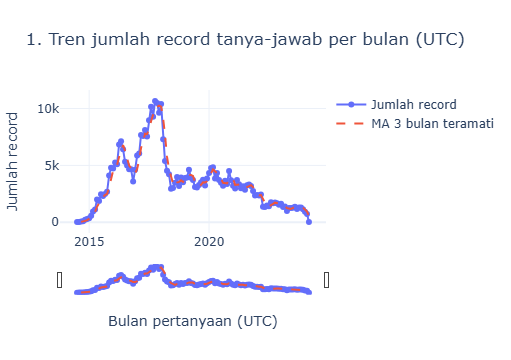

Disimpan: data/processed/eda_figures/01_tren_bulanan.html


PosixPath('/home/jovyan/work/data/processed/eda_figures/01_tren_bulanan.html')

In [5]:
fig1 = go.Figure()
fig1.add_trace(go.Scatter(
    x=monthly['bulan'].to_list(), y=monthly['jumlah_record'].to_list(),
    name='Jumlah record', mode='lines+markers',
))
fig1.add_trace(go.Scatter(
    x=monthly['bulan'].to_list(), y=monthly['MA3_bulan_teramati'].to_list(),
    name='MA 3 bulan teramati', mode='lines', line=dict(dash='dash'),
))
fig1.update_layout(
    title='1. Tren jumlah record tanya-jawab per bulan (UTC)',
    xaxis_title='Bulan pertanyaan (UTC)', yaxis_title='Jumlah record',
    hovermode='x unified',
)
fig1.update_xaxes(rangeslider_visible=True)
publish(fig1, '01_tren_bulanan.html')

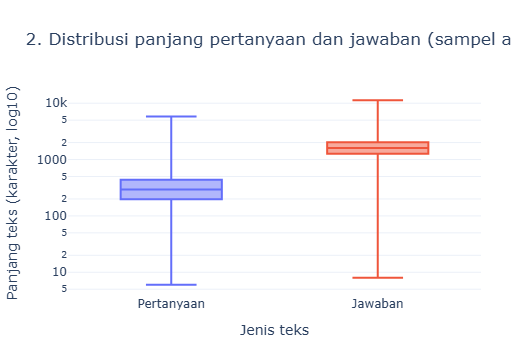

Disimpan: data/processed/eda_figures/02_distribusi_panjang_teks.html


PosixPath('/home/jovyan/work/data/processed/eda_figures/02_distribusi_panjang_teks.html')

In [6]:
fig2 = go.Figure()
for field, label in [('question_length', 'Pertanyaan'), ('answer_length', 'Jawaban')]:
    values = [v for v in numeric_sample[field].to_list() if v is not None and v > 0]
    fig2.add_trace(go.Box(y=values, name=label, boxpoints=False))
fig2.update_layout(
    title='2. Distribusi panjang pertanyaan dan jawaban (sampel acak)',
    xaxis_title='Jenis teks', yaxis_title='Panjang teks (karakter, log10)',
    showlegend=False,
)
fig2.update_yaxes(type='log')
publish(fig2, '02_distribusi_panjang_teks.html')

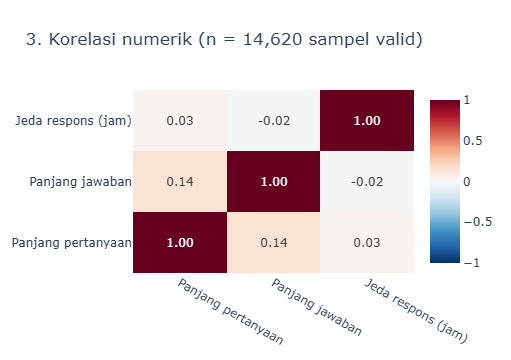

Disimpan: data/processed/eda_figures/03_korelasi_heatmap.html


PosixPath('/home/jovyan/work/data/processed/eda_figures/03_korelasi_heatmap.html')

In [7]:
corr_df = numeric_sample.filter(
    pl.col('response_hours').is_not_null() &
    pl.col('response_hours').is_between(0, MAX_RESPONSE_HOURS) &
    (pl.col('question_length') <= summary['p99_pertanyaan']) &
    (pl.col('answer_length') <= summary['p99_jawaban'])
).select(['question_length', 'answer_length', 'response_hours']).drop_nulls()
if corr_df.height < 3:
    raise ValueError('Terlalu sedikit record valid untuk korelasi; periksa hasil parsing tanggal M2.')

corr_features = ['question_length', 'answer_length', 'response_hours']
X = corr_df.to_numpy().astype(float)
with np.errstate(invalid='ignore', divide='ignore'):
    corr_matrix = np.corrcoef(X, rowvar=False)
annotation = [['—' if math.isnan(float(x)) else f'{x:.2f}' for x in row] for row in corr_matrix]
labels_corr = ['Panjang pertanyaan', 'Panjang jawaban', 'Jeda respons (jam)']
fig3 = go.Figure(go.Heatmap(
    x=labels_corr, y=labels_corr, z=corr_matrix,
    zmin=-1, zmax=1, zmid=0,
    colorscale='RdBu', reversescale=True,
    text=annotation, texttemplate='%{text}',
    hovertemplate='%{x} vs %{y}<br>Pearson r: %{z:.3f}<extra></extra>',
))
fig3.update_layout(title=f'3. Korelasi numerik (n = {corr_df.height:,} sampel valid)')
publish(fig3, '03_korelasi_heatmap.html')

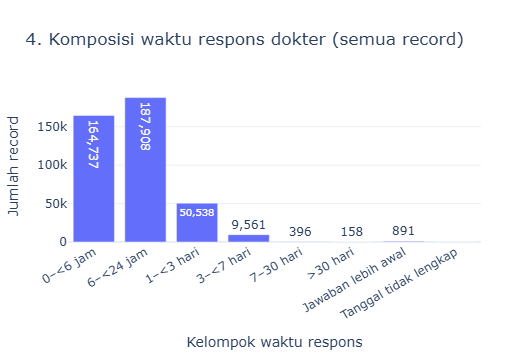

Disimpan: data/processed/eda_figures/04_komposisi_respons.html


PosixPath('/home/jovyan/work/data/processed/eda_figures/04_komposisi_respons.html')

In [8]:
bucket_order = [
    '0–<6 jam', '6–<24 jam', '1–<3 hari', '3–<7 hari',
    '7–30 hari', '>30 hari', 'Jawaban lebih awal', 'Tanggal tidak lengkap',
]
buckets = metrics.group_by('response_bucket').agg(pl.len().alias('jumlah')).collect(engine='streaming')
bucket_map = dict(zip(buckets['response_bucket'].to_list(), buckets['jumlah'].to_list()))
counts_bucket = [int(bucket_map.get(v, 0)) for v in bucket_order]
assert sum(counts_bucket) == summary['jumlah_record'], 'Sebagian record gagal dikategorikan'
pl.DataFrame({'kelompok_jeda': bucket_order, 'jumlah_record': counts_bucket}).write_csv(
    PROCESSED / 'eda_response_buckets.csv'
)
fig4 = px.bar(
    x=bucket_order, y=counts_bucket,
    labels={'x': 'Kelompok waktu respons', 'y': 'Jumlah record'},
    title='4. Komposisi waktu respons dokter (semua record)',
    text_auto=',',
)
fig4.update_xaxes(categoryorder='array', categoryarray=bucket_order, tickangle=-30)
publish(fig4, '04_komposisi_respons.html')

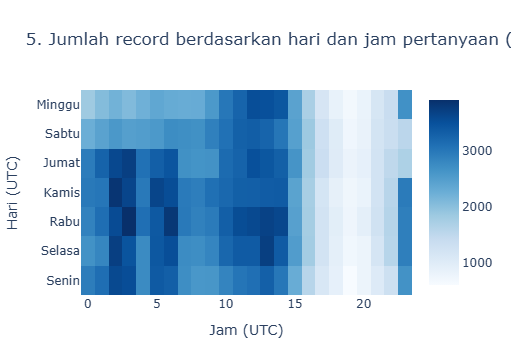

Disimpan: data/processed/eda_figures/05_heatmap_hari_jam.html


PosixPath('/home/jovyan/work/data/processed/eda_figures/05_heatmap_hari_jam.html')

In [9]:
weekday_names = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
weekday_hour = (
    metrics.filter(pl.col('weekday_utc').is_not_null() & pl.col('hour_utc').is_not_null())
    .group_by(['weekday_utc', 'hour_utc'])
    .agg(pl.len().alias('jumlah_record'))
    .collect(engine='streaming')
)
heat = np.zeros((7, 24), dtype=int)
for r in weekday_hour.iter_rows(named=True):
    day, hour = int(r['weekday_utc']), int(r['hour_utc'])
    if 1 <= day <= 7 and 0 <= hour < 24:
        heat[day - 1, hour] += int(r['jumlah_record'])
assert int(heat.sum()) == summary['tanggal_pertanyaan_valid']
fig5 = go.Figure(go.Heatmap(
    z=heat, x=list(range(24)), y=weekday_names,
    colorscale='Blues',
    hovertemplate='%{y} pukul %{x}:00 UTC<br>%{z:,} record<extra></extra>',
))
fig5.update_layout(
    title='5. Jumlah record berdasarkan hari dan jam pertanyaan (UTC)',
    xaxis_title='Jam (UTC)', yaxis_title='Hari (UTC)',
)
publish(fig5, '05_heatmap_hari_jam.html')

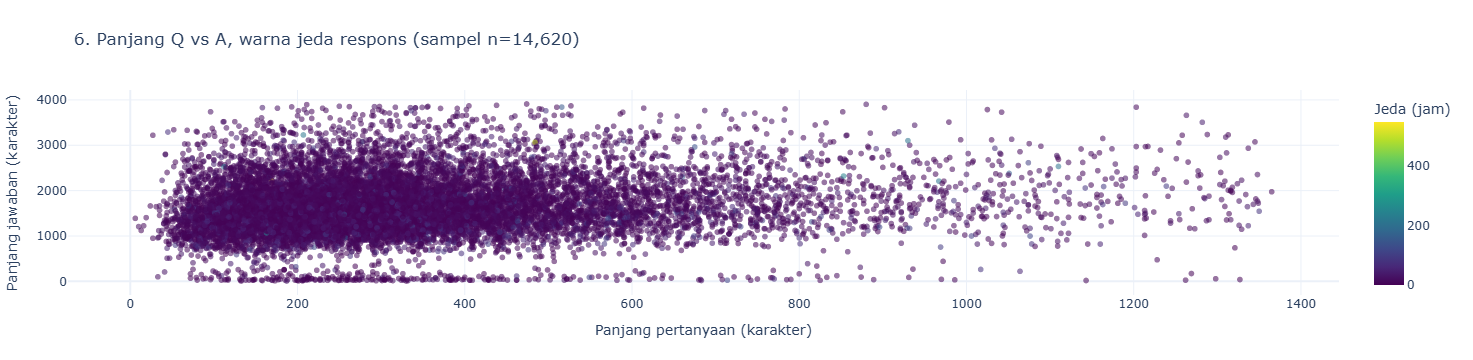

Disimpan: data/processed/eda_figures/06_scatter_multidimensi.html


PosixPath('/home/jovyan/work/data/processed/eda_figures/06_scatter_multidimensi.html')

In [13]:
scatter_df = numeric_sample.filter(
    pl.col('response_hours').is_not_null() &
    pl.col('response_hours').is_between(0, MAX_RESPONSE_HOURS) &
    (pl.col('question_length') <= summary['p99_pertanyaan']) &
    (pl.col('answer_length') <= summary['p99_jawaban'])
)
if scatter_df.is_empty():
    raise ValueError('Tidak ada data valid untuk scatter multidimensi; cek waktu di M2.')
fig6 = go.Figure(go.Scattergl(
    x=scatter_df['question_length'].to_list(),
    y=scatter_df['answer_length'].to_list(),
    mode='markers',
    marker=dict(
        size=6, opacity=0.55,
        color=scatter_df['response_hours'].to_list(),
        colorscale='Viridis', showscale=True,
        colorbar=dict(title='Jeda (jam)'),
    ),
    hovertemplate='Pertanyaan %{x:,} karakter<br>Jawaban %{y:,} karakter<extra></extra>',
))
fig6.update_layout(
    title=f'6. Panjang Q vs A, warna jeda respons (sampel n={scatter_df.height:,})',
    xaxis_title='Panjang pertanyaan (karakter)',
    yaxis_title='Panjang jawaban (karakter)',
)
publish(fig6, '06_scatter_multidimensi.html')

## Bagian 4: Rumusan 5 Insight Analitik Utama

Tuliskan minimal 5 temuan atau wawasan penting yang Anda peroleh dari visualisasi di atas:

1. **Insight 1 — Aktivitas temporal.** Dari 117 bulan yang memiliki data, puncak jumlah record Q&A terjadi pada 2017-10 sebanyak 10,672 record. Interpretasi: menunjukkan periode paling ramai dalam arsip platform, bukan epidemiologi nasional.

2. **Insight 2 — Ketimpangan panjang teks.** Median pertanyaan 293 karakter dan median jawaban 1,610 karakter (rasio 5.49×). Sebanyak 22,975 pertanyaan dan 13,212 jawaban ditandai outlier IQR pada Milestone 2; HTML turut dihitung dalam panjang karakter.

3. **Insight 3 — Korelasi panjang teks.** Pearson r antara panjang pertanyaan dan jawaban adalah 0.144 pada 14,620 record sampel yang memenuhi batas grafik. Ini asosiasi observasional, bukan bukti panjang pertanyaan menyebabkan panjang jawaban.

4. **Insight 4 — Waktu respons.** Dari 413,298 record dengan jeda respons nonnegatif, kelompok paling banyak adalah 6–<24 jam (187,908 record). Ada 891 record dengan jeda negatif dan 0 dengan timestamp tidak lengkap; keduanya dipisahkan dari analisis waktu respons normal.

5. **Insight 5 — Siklus hari dan jam (UTC).** Sel hari-jam terpadat adalah Rabu pukul 03:00 UTC dengan 3,914 record. Jangan mengonversi temuan ini menjadi pola jam lokal pasien karena lokasi/waktu setempat tidak ada.

6. **Insight 6 — Rekomendasi kualitas data.** Untuk pengembangan analisis, tinjau 891 anomali urutan waktu, 0 record tanggal tak lengkap, dan outlier panjang teks secara audit berbasis sampel yang aman. Jangan hapus ID berulang begitu saja, karena bisa merepresentasikan jawaban berbeda.

**Batasan:** Q&A platform ≠ prevalensi penyakit; waktu UTC; tanpa informasi geografis terverifikasi; korelasi bukan sebab akibat.
